# Notebook 04: Dokumentasi Lengkap Topic Modeling (LDA), Normalisasi Slang & Typo, Clause-Level ABSA, Dashboard Komparasi, dan Pengujian 7 Skenario Prototipe

**Mata Kuliah**: AM552B - Data Science of Information Systems (S1 Sistem Informasi, FTI UKSW)  
**Proyek**: Analisis Komparatif Sentimen Berbasis Aspek (ABSA) dan Pemodelan Topik Pengalaman Pengguna terhadap Aplikasi Mobile Generative AI di Indonesia  
**Tujuan Notebook**: Melengkapi dokumentasi *reproducible* `.ipynb` atas seluruh kegiatan & klaim pada *Progress Report Kelompok 2* yang sebelumnya hanya tersimpan pada skrip Python terpisah:
1. **Verifikasi Kamus Slang (1.100 Entri) & Koreksi Typo Otomatis** (*Smart Elongation Reduction* & *Damerau-Levenshtein*).
2. **Unsupervised Topic Modeling (LDA)** — 5 klaster topik keluhan, 5 klaster topik pujian, serta bedah kasus **Character.AI (1,58)** & **DeepSeek (3,77)**.
3. **Clause-Level ABSA** — Pemecahan kalimat campuran berdasarkan konjungsi kontras (*"tapi"*, *"namun"*, *"padahal"*) untuk sentimen spesifik per aspek.
4. **Discrepancy-Adjusted Rating, Matriks Kepuasan 4 Aspek (NSS) & Verifikasi Time-Series Dashboard**.
5. **Audit Artefak Model `.joblib` (0,91 MB) & Eksekusi Live 7 Skenario Pengujian Prototipe**.

In [1]:
import os
import re
import sys
import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

ROOT_DIR = os.path.abspath("..")
PROTOTYPE_DIR = os.path.join(ROOT_DIR, "prototype")
if PROTOTYPE_DIR not in sys.path:
    sys.path.insert(0, PROTOTYPE_DIR)

from core_predictor import (
    MODEL_PATH,
    SLANG_PATH,
    BENCHMARK_JSON_PATH,
    get_fresh_slang_dict,
    load_trained_artifact,
    build_typo_vocab_index,
    preprocess_text_indonesian,
    split_into_clean_clauses,
    predict_single_review,
    predict_batch_dataframe,
)

RAW_CSV_PATH = os.path.join(ROOT_DIR, "dataset", "RAW_DATASET_GENAI_INDONESIA_AM522B.csv")
df = pd.read_csv(RAW_CSV_PATH, low_memory=False)
artifact = load_trained_artifact()
vocab_index = build_typo_vocab_index(artifact["pipeline"])

print(f"Dataset terbaca : {len(df):,} baris x {df.shape[1]} kolom")
print(f"Rentang waktu   : {df['at'].min()} s/d {df['at'].max()}")
print(f"Model produksi  : {artifact['model_name']}")


Dataset terbaca : 71,221 baris x 11 kolom
Rentang waktu   : 2023-05-31 07:37:14 s/d 2026-11-17 16:00:19
Model produksi  : Tuned Logistic Regression (TF-IDF 1-2 Gram, C=0.5, Balanced)


---
## 1. Verifikasi Kamus Normalisasi Slang (1.100 Entri) & Koreksi Typo Otomatis
Mendokumentasikan pembaruan kamus bahasa tidak baku (`03_data_preparation/slang_dictionary_id.json`) dan mekanisme koreksi salah ketik otomatis pada `prototype/core_predictor.py` menggunakan dua tahap:
1. **Smart Elongation Reduction**: memendekkan huruf berulang berlebihan (mis. `baguuusss` → `bagus`, `lemottt` → `lambat`).
2. **Fuzzy Damerau-Levenshtein**: mengoreksi salah ketik OOV panjang ≥ 4 huruf (mis. `akursi` → `akurasi`, `bagsu` → `bagus`).

In [2]:
slang_dict = get_fresh_slang_dict()
print(f"Total entri kamus slang (slang_dictionary_id.json): {len(slang_dict):,} entri")

sample_keys = ["gk", "ga", "bgt", "apk", "lemot", "eror", "udh", "blm", "mantul", "ngawur"]
sample_slang_df = pd.DataFrame([
    {"Kata Slang / Singkatan": k, "Bentuk Baku": slang_dict.get(k, "(tidak ada)")}
    for k in sample_keys
])
print("\nContoh Pemetaan Kamus Slang:")
display(sample_slang_df)

# Uji Koreksi Typo Otomatis & Elongation Reduction
typo_samples = [
    "akursi jawabannya baguuusss bgt tp apk sering lemottt",
    "bagsu sekali sangat membatnu tugas kuliah",
    "servre sibuk terus dan ga bisa logni",
    "jawban ai sering ngawur dan eror saat updte",
]
typo_rows = []
for raw_s in typo_samples:
    clean_s, corrs = preprocess_text_indonesian(
        raw_s, slang_dict=slang_dict, vocab_index=vocab_index, return_corrections=True
    )
    corr_txt = ", ".join(f"{c['asal']} -> {c['koreksi']}" for c in corrs) if corrs else "-"
    typo_rows.append({
        "Teks Asli (Slang + Typo)": raw_s,
        "Hasil Normalisasi": clean_s,
        "Koreksi Typo Otomatis": corr_txt,
    })

print("\nHasil Uji Koreksi Typo & Normalisasi Slang Otomatis:")
display(pd.DataFrame(typo_rows))


Total entri kamus slang (slang_dictionary_id.json): 1,100 entri

Contoh Pemetaan Kamus Slang:

Hasil Uji Koreksi Typo & Normalisasi Slang Otomatis:


,Kata Slang / Singkatan,Bentuk Baku
0,gk,tidak
1,ga,tidak
2,bgt,banget
3,apk,aplikasi
4,lemot,lambat
5,eror,error
6,udh,sudah
7,blm,belum
8,mantul,mantap
9,ngawur,acau


,Teks Asli (Slang + Typo),Hasil Normalisasi,Koreksi Typo Otomatis
0,akursi jawabannya baguuusss bgt tp apk sering lemottt,akurasi jawabannya baguuss banget tapi aplikasi sering lambat,akursi -> akurasi
1,bagsu sekali sangat membatnu tugas kuliah,bagus sekali sangat membantu tugas kuliah,"bagsu -> bagus, membatnu -> membantu"
2,servre sibuk terus dan ga bisa logni,server sibuk terus dan tidak bisa masuk,"servre -> server, logni -> masuk"
3,jawban ai sering ngawur dan eror saat updte,jawaban ai sering acau dan error saat update,"jawban -> jawaban, updte -> update"


---
## 2. Unsupervised Topic Modeling (Latent Dirichlet Allocation / LDA)
Mengekstraksi klaster topik tanpa label secara otomatis dari 71.221 ulasan menggunakan `CountVectorizer(ngram_range=(1, 2), max_features=3000, min_df=3)` dan `LatentDirichletAllocation`:
- **5 Klaster Topik Keluhan Utama** (korpus Bintang 1–2)
- **5 Klaster Topik Pujian Utama** (korpus Bintang 4–5)
- **Bedah Kasus Aplikasi Spesifik**: Mengapa **Character.AI** anjlok ke **1,58** dan **DeepSeek** tertahan di **3,77**.

Korpus LDA Keluhan (Bintang 1-2): 16,629 ulasan
Korpus LDA Pujian  (Bintang 4-5): 34,110 ulasan

=== 5 KLASTER TOPIK KELUHAN GLOBAL (BINTANG 1-2) ===

=== 5 KLASTER TOPIK PUJIAN GLOBAL (BINTANG 4-5) ===

=== BEDAH KASUS CHARACTER.AI (Rata-rata Rating 1,58 | N=9,787) ===

=== BEDAH KASUS DEEPSEEK (Rata-rata Rating 3,77 | N=1,749) ===


,Topik,Kata Kunci Dominan (LDA)
0,Topik 1,"makin, tidak, jelek, malah, update, jelas, tidak jelas, error"
1,Topik 2,"you, old, update, age, but, back, like, now"
2,Topik 3,"tidak, iklan, banyak, bug, menolong, limit, gambar, membuat"
3,Topik 4,"tidak, sekarang, dulu, update, tapi, bagus, lambat, lama"
4,Topik 5,"tidak, verifikasi, tiba, harus, padahal, umur, tapi, usia"


,Topik,Kata Kunci Dominan (LDA)
0,Topik 1,"mantap, bagus, membantu, cepat, mudah, chatgpt, benar, jawaban"
1,Topik 2,"bagus, kasih, terima, terima kasih, tidak, menolong, tapi, gpt"
2,Topik 3,"tidak, tapi, membuat, biasa, hanya, luar, luar biasa, gambar"
3,Topik 4,"membantu, bagus, sekali, terbaik, bagus sekali, bagus membantu, suka, membantu sekali"
4,Topik 5,"good, fitur, bermanfaat, very, you, terbaik, semoga, coba"


,Topik,Kata Kunci Keluhan Character.AI
0,Topik 1,"you, old, update, age, back, but, now"
1,Topik 2,"tidak, makin, dulu, sekarang, update, banyak, iklan"
2,Topik 3,"tidak, verifikasi, tapi, harus, hanya, padahal, menolong"


,Topik,Kata Kunci Keluhan DeepSeek
0,Topik 1,"tidak, tapi, bagus, lama, padahal, deepseek, hanya"
1,Topik 2,"server, busy, server busy, bahasa, masih, sering, tidak"
2,Topik 3,"server, lambat, sibuk, sering, servernya, busy, menolong"


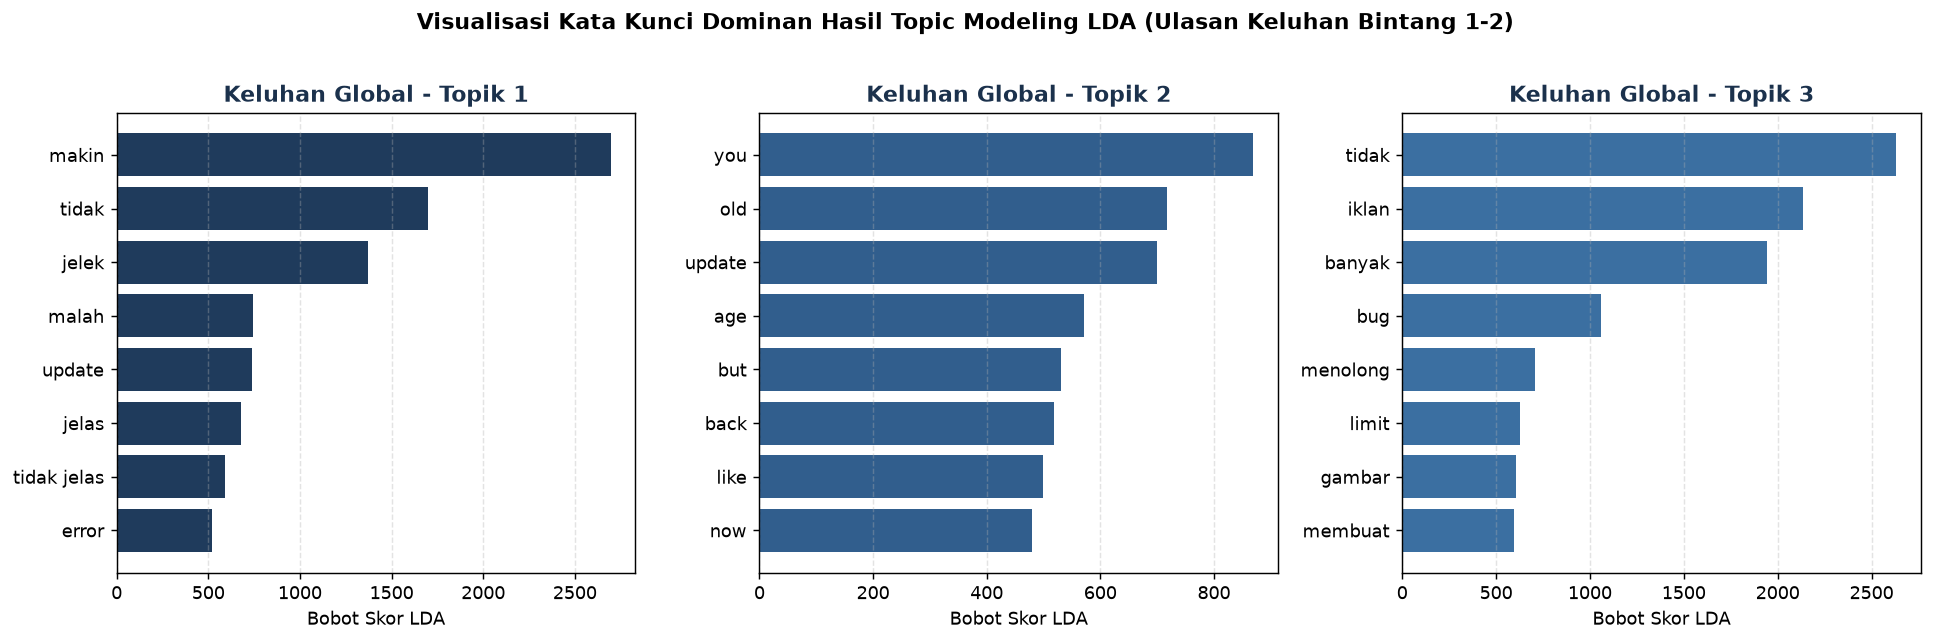

In [3]:
CUSTOM_STOPWORDS = {
    "yang", "di", "dan", "ini", "itu", "dengan", "untuk", "pada", "dari", "ke",
    "dalam", "saya", "aku", "nya", "ya", "saja", "juga", "atau", "ada", "kalau",
    "karena", "sudah", "bisa", "sama", "jadi", "lebih", "mau", "apa", "lagi",
    "buat", "kan", "lah", "kok", "sih", "deh", "dong", "nih", "tuh", "pun",
    "kami", "kita", "mereka", "dia", "kamu", "anda", "seperti", "saat", "ketika",
    "oleh", "sebagai", "bahwa", "adalah", "yaitu", "the", "to", "and", "of",
    "in", "is", "it", "for", "on", "with", "as", "this", "that", "aplikasi", "apk",
    "app", "chat", "ai", "banget", "bgt", "sangat", "tolong", "bintang"
}

def clean_for_lda(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    cleaned = []
    for t in text.split():
        w = slang_dict.get(t, t)
        if len(w) >= 3 and w not in CUSTOM_STOPWORDS:
            cleaned.append(w)
    return " ".join(cleaned)

def run_lda_topics(corpus, n_topics=5, n_top_words=8, max_features=3000):
    vec = CountVectorizer(max_features=max_features, ngram_range=(1, 2), min_df=3)
    dtm = vec.fit_transform(corpus)
    feat_names = vec.get_feature_names_out()
    lda = LatentDirichletAllocation(
        n_components=n_topics, random_state=42, max_iter=10,
        batch_size=512, learning_method="online", n_jobs=1
    )
    lda.fit(dtm)
    res = []
    for idx, comp in enumerate(lda.components_):
        top_idx = comp.argsort()[:-n_top_words - 1:-1]
        res.append({
            "Topik": f"Topik {idx + 1}",
            "Top Keywords": ", ".join(feat_names[i] for i in top_idx),
            "words": [feat_names[i] for i in top_idx],
            "weights": [float(comp[i]) for i in top_idx],
        })
    return res

df["lda_clean"] = df["content"].apply(clean_for_lda)
neg_corpus = df[df["score"].isin([1, 2]) & (df["lda_clean"].str.len() > 5)]["lda_clean"].tolist()
pos_corpus = df[df["score"].isin([4, 5]) & (df["lda_clean"].str.len() > 5)]["lda_clean"].tolist()

print(f"Korpus LDA Keluhan (Bintang 1-2): {len(neg_corpus):,} ulasan")
print(f"Korpus LDA Pujian  (Bintang 4-5): {len(pos_corpus):,} ulasan")

neg_topics = run_lda_topics(neg_corpus, n_topics=5, n_top_words=8)
pos_topics = run_lda_topics(pos_corpus, n_topics=5, n_top_words=8)

print("\n=== 5 KLASTER TOPIK KELUHAN GLOBAL (BINTANG 1-2) ===")
display(pd.DataFrame([{"Topik": t["Topik"], "Kata Kunci Dominan (LDA)": t["Top Keywords"]} for t in neg_topics]))

print("\n=== 5 KLASTER TOPIK PUJIAN GLOBAL (BINTANG 4-5) ===")
display(pd.DataFrame([{"Topik": t["Topik"], "Kata Kunci Dominan (LDA)": t["Top Keywords"]} for t in pos_topics]))

# Bedah Kasus Aplikasi Spesifik: Character.AI & DeepSeek
cai_corpus = df[(df["app_name"] == "Character.AI") & df["score"].isin([1, 2]) & (df["lda_clean"].str.len() > 5)]["lda_clean"].tolist()
deep_corpus = df[(df["app_name"] == "DeepSeek - AI Assistant") & df["score"].isin([1, 2, 3]) & (df["lda_clean"].str.len() > 5)]["lda_clean"].tolist()

cai_topics = run_lda_topics(cai_corpus, n_topics=3, n_top_words=7)
deep_topics = run_lda_topics(deep_corpus, n_topics=3, n_top_words=7)

print(f"\n=== BEDAH KASUS CHARACTER.AI (Rata-rata Rating 1,58 | N={len(cai_corpus):,}) ===")
display(pd.DataFrame([{"Topik": t["Topik"], "Kata Kunci Keluhan Character.AI": t["Top Keywords"]} for t in cai_topics]))

print(f"\n=== BEDAH KASUS DEEPSEEK (Rata-rata Rating 3,77 | N={len(deep_corpus):,}) ===")
display(pd.DataFrame([{"Topik": t["Topik"], "Kata Kunci Keluhan DeepSeek": t["Top Keywords"]} for t in deep_topics]))

# Visualisasi Bobot Kata Kunci Top-3 Topik Keluhan Global
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), dpi=120)
palette = ["#1F3B5C", "#315E8D", "#3B6FA1"]
for i in range(3):
    t = neg_topics[i]
    w_rev = t["words"][::-1]
    v_rev = t["weights"][::-1]
    axes[i].barh(w_rev, v_rev, color=palette[i])
    axes[i].set_title(f"Keluhan Global - {t['Topik']}", fontweight="bold", color="#1B314C")
    axes[i].set_xlabel("Bobot Skor LDA")
    axes[i].grid(axis="x", linestyle="--", alpha=0.35)
plt.suptitle("Visualisasi Kata Kunci Dominan Hasil Topic Modeling LDA (Ulasan Keluhan Bintang 1-2)", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


---
## 3. Clause-Level ABSA (Analisis Sentimen per Aspek Berbasis Klausa)
Ulasan campuran sering memuat pujian pada satu aspek namun keluhan pada aspek lain. Modul `split_into_clean_clauses()` dan `enrich_aspects_with_sentiment()` memecah kalimat berdasarkan tanda baca dan kata hubung kontras (*tapi*, *tetapi*, *namun*, *padahal*, *cuma*, *sayang*) agar tiap aspek menerima label sentimen spesifiknya.

In [4]:
mixed_examples = [
    ("jawabannya akurat, tapi kuota cepat habis dan mahal", 3, "ChatGPT (OpenAI)"),
    ("jawabannya akurat, tapi kuotanya dikit", 3, "ChatGPT (OpenAI)"),
    ("AI nya pintar banget buat bantu tugas coding, namun server sering sibuk dan lemot", 4, "DeepSeek - AI Assistant"),
    ("Bahasa Indonesia sudah luwes dan cepat, cuma harga langganan plus terlalu mahal", 4, "Google Gemini"),
    ("Tampilan UI nyaman dan respons cepat, tapi jawaban kadang ngawur dan halusinasi", 3, "Perplexity - Ask Anything"),
    ("Saya kasih bintang 5 biar dibaca developer, aplikasi makin update makin lemot dan banyak iklan", 5, "Character.AI"),
]

clause_rows = []
for raw_txt, stars, app_nm in mixed_examples:
    clauses = split_into_clean_clauses(raw_txt, vocab_index=vocab_index)
    res = predict_single_review(raw_txt, star_rating=stars, app_name=app_nm, artifact=artifact)
    asp_summary = " | ".join(
        f"{a['aspect_label']} -> {a.get('aspect_sentiment', res['predicted_sentiment'])} ({a.get('aspect_confidence', res['confidence'])*100:.0f}%)"
        for a in res["detected_aspects"]
    )
    clause_rows.append({
        "Ulasan Campuran": raw_txt,
        "Rating": stars,
        "Klausa Terpecah": " // ".join(clauses),
        "Sentimen Global": f"{res['predicted_sentiment']} ({res['confidence']*100:.1f}%)",
        "Sentimen per Aspek (Clause-Level ABSA)": asp_summary,
        "Discrepancy": "YA" if res["is_discrepancy"] else "Konsisten",
    })

pd.set_option("display.max_colwidth", None)
display(pd.DataFrame(clause_rows))


,Ulasan Campuran,Rating,Klausa Terpecah,Sentimen Global,Sentimen per Aspek (Clause-Level ABSA),Discrepancy
0,"jawabannya akurat, tapi kuota cepat habis dan mahal",3,jawabannya akurat // kuota cepat habis dan mahal,Positif (59.1%),"A1: Akurasi & Kecerdasan AI -> Positif (70%) | A2: Harga & Limitasi Kuota -> Negatif (84%) | A3: Performa, UI/UX & Server -> Negatif (84%)",Konsisten
1,"jawabannya akurat, tapi kuotanya dikit",3,jawabannya akurat // kuotanya dikit,Positif (53.2%),A1: Akurasi & Kecerdasan AI -> Positif (70%),Konsisten
2,"AI nya pintar banget buat bantu tugas coding, namun server sering sibuk dan lemot",4,ai nya pintar banget buat membantu tugas coding // server sering sibuk dan lambat,Netral (57.0%),"A1: Akurasi & Kecerdasan AI -> Positif (92%) | A3: Performa, UI/UX & Server -> Negatif (84%)",YA
3,"Bahasa Indonesia sudah luwes dan cepat, cuma harga langganan plus terlalu mahal",4,bahasa indonesia sudah luwes dan cepat // hanya harga berlangganan plus terlalu mahal,Netral (42.8%),"A2: Harga & Limitasi Kuota -> Negatif (52%) | A3: Performa, UI/UX & Server -> Positif (69%) | A4: Bahasa Indonesia & Konteks Lokal -> Positif (69%)",YA
4,"Tampilan UI nyaman dan respons cepat, tapi jawaban kadang ngawur dan halusinasi",3,tampilan ui nyaman dan respons cepat // jawaban kadang acau dan halusinasi,Netral (60.4%),"A1: Akurasi & Kecerdasan AI -> Negatif (84%) | A3: Performa, UI/UX & Server -> Positif (83%)",Konsisten
5,"Saya kasih bintang 5 biar dibaca developer, aplikasi makin update makin lemot dan banyak iklan",5,saya kasih bintang 5 agar dibaca developer // aplikasi makin update makin lambat dan banyak iklan,Negatif (67.8%),"A2: Harga & Limitasi Kuota -> Negatif (71%) | A3: Performa, UI/UX & Server -> Negatif (71%)",YA


---
## 4. Discrepancy-Adjusted Rating, Matriks Kepuasan 4 Aspek (NSS) & Verifikasi Time-Series Dashboard
Mendokumentasikan data produksi yang ditampilkan pada **Menu 1 (Dashboard Komparasi)** di aplikasi Streamlit: perbandingan *Rating Play Store* vs *Rating Aktual Terkoreksi*, Net Sentiment Score (NSS) per aspek A1–A4, serta verifikasi file agregasi rentang tanggal (`models/dashboard_daily_metrics.csv`).

=== PERBANDINGAN RATING PLAY STORE VS RATING AKTUAL (DISCREPANCY-ADJUSTED) ===

=== MATRIKS NET SENTIMENT SCORE (NSS %) PER 4 ASPEK LAYANAN ===

Verifikasi Dashboard Time-Series (dashboard_daily_metrics.csv):
  - Total baris agregasi harian : 4,409
  - Kolom tersedia              : ['date', 'app_name', 'n_reviews', 'sum_score', 'sum_adj_score', 'disc_high_neg', 'disc_low_pos', 'a1_n', 'a1_pos', 'a1_neg', 'a2_n', 'a2_pos', 'a2_neg', 'a3_n', 'a3_pos', 'a3_neg', 'a4_n', 'a4_pos', 'a4_neg']
  - Rentang tanggal filter      : 2023-05-31 s/d 2026-11-17


,Nama Aplikasi,Jumlah Ulasan,Rating Play Store,Rating Aktual (Terkoreksi),Selisih Rating,Total Discrepancy (%),Bintang 4-5 Teks Negatif,Bintang 1-2 Teks Positif
0,ChatGPT (OpenAI),22000,4.46,4.43,-0.03,3.13,437,252
1,Google Gemini,12600,4.29,4.27,-0.02,4.17,302,223
2,Character.AI,12000,1.58,1.50,-0.08,5.97,535,181
3,Perplexity - Ask Anything,8043,4.54,4.52,-0.02,2.47,131,68
4,Microsoft Copilot,5459,4.65,4.62,-0.03,2.95,116,45
5,DeepSeek - AI Assistant,5374,3.77,3.65,-0.12,7.26,323,67
6,Claude by Anthropic,4009,3.85,3.74,-0.11,5.84,199,35
7,Poe - Fast AI Chat,1736,4.66,4.58,-0.08,4.67,66,15


,A1: Akurasi AI,A2: Harga & Kuota,A3: Performa & Server,A4: Bahasa Indonesia
Nama Aplikasi,,,,
ChatGPT (OpenAI),77.2,-30.4,-18.1,22.2
Google Gemini,60.4,-30.7,-15.9,-16.0
Character.AI,-81.3,-87.9,-91.1,-75.3
Perplexity - Ask Anything,82.9,-5.5,40.0,8.8
Microsoft Copilot,84.1,42.4,14.8,45.0
DeepSeek - AI Assistant,33.1,13.7,-24.6,-0.8
Claude by Anthropic,53.1,-25.8,-50.5,-2.0
Poe - Fast AI Chat,88.9,-21.1,15.4,23.5


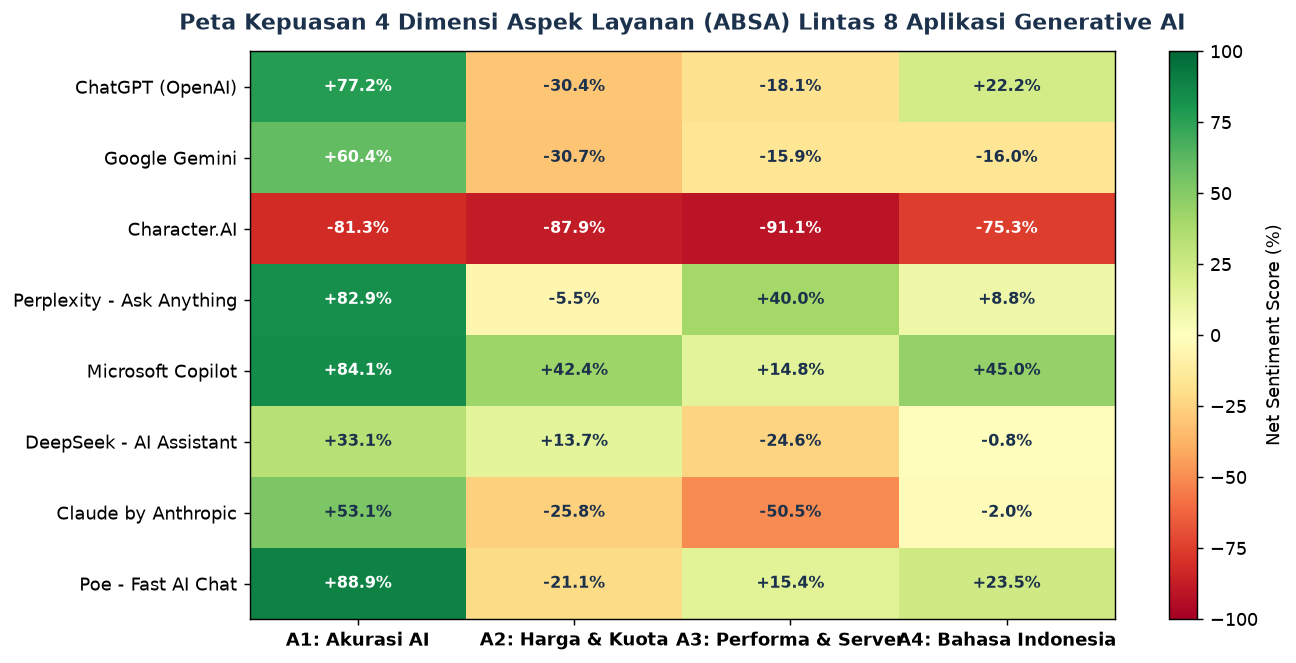

In [5]:
with open(BENCHMARK_JSON_PATH, "r", encoding="utf-8") as f:
    bench = json.load(f)

df_rating_comp = pd.DataFrame(bench["rating_comparison"])
print("=== PERBANDINGAN RATING PLAY STORE VS RATING AKTUAL (DISCREPANCY-ADJUSTED) ===")
display(df_rating_comp)

df_asp_num = pd.DataFrame(bench["aspect_numeric_matrix"]).set_index("Nama Aplikasi")
print("\n=== MATRIKS NET SENTIMENT SCORE (NSS %) PER 4 ASPEK LAYANAN ===")
display(df_asp_num)

# Heatmap Matriks NSS 4 Aspek Lintas 8 Aplikasi
fig, ax = plt.subplots(figsize=(10.5, 5.2), dpi=120)
im = ax.imshow(df_asp_num.values, cmap="RdYlGn", vmin=-100, vmax=100, aspect="auto")
ax.set_xticks(range(len(df_asp_num.columns)))
ax.set_xticklabels(df_asp_num.columns, fontweight="bold")
ax.set_yticks(range(len(df_asp_num.index)))
ax.set_yticklabels(df_asp_num.index)
for i in range(len(df_asp_num.index)):
    for j in range(len(df_asp_num.columns)):
        val = df_asp_num.values[i, j]
        txt_col = "white" if abs(val) > 55 else "#1B314C"
        ax.text(j, i, f"{val:+.1f}%", ha="center", va="center", fontweight="bold", color=txt_col, fontsize=9)
plt.colorbar(im, ax=ax, label="Net Sentiment Score (%)")
ax.set_title("Peta Kepuasan 4 Dimensi Aspek Layanan (ABSA) Lintas 8 Aplikasi Generative AI", fontweight="bold", color="#1B314C", pad=12)
plt.tight_layout()
plt.show()

daily_path = os.path.join(ROOT_DIR, "models", "dashboard_daily_metrics.csv")
if os.path.exists(daily_path):
    df_daily = pd.read_csv(daily_path)
    print(f"\nVerifikasi Dashboard Time-Series (dashboard_daily_metrics.csv):")
    print(f"  - Total baris agregasi harian : {len(df_daily):,}")
    print(f"  - Kolom tersedia              : {list(df_daily.columns)}")
    if "date" in df_daily.columns:
        print(f"  - Rentang tanggal filter      : {df_daily['date'].min()} s/d {df_daily['date'].max()}")


---
## 5. Verifikasi Artefak Model `.joblib` & Pengujian 7 Skenario Prototipe
Memverifikasi spesifikasi aktual file model tersimpan (`models/genai_absa_pipeline.joblib`), metrik evaluasi eksak 4 desimal pada data uji (14.245 baris), serta mengeksekusi secara langsung seluruh **7 skenario pengujian prototipe** (Input Normal Positif & Negatif, Input Ekstrem Slang/Discrepancy & >3.000 Karakter, Input Kosong, Input Angka/Simbol, dan CSV Salah Format).

In [6]:
size_bytes = os.path.getsize(MODEL_PATH)
size_mb = size_bytes / (1024 * 1024)
vec = artifact["pipeline"].named_steps["tfidf"]
clf = artifact["pipeline"].named_steps["clf"]

print("=== SPESIFIKASI AKTUAL ARTEFAK MODEL PRODUKSI ===")
print(f"Path file        : {MODEL_PATH}")
print(f"Ukuran file      : {size_mb:.2f} MB ({size_bytes:,} bytes)")
print(f"Model terpilih   : {artifact['model_name']}")
print(f"TF-IDF features  : {len(vec.vocabulary_):,} fitur (ngram_range={vec.ngram_range})")
print(f"Hyperparameter   : C={clf.C}, class_weight={clf.class_weight}")

print("\n=== METRIK EVALUASI EKSAK (DATA UJI 20% = 14.245 ULASAN) ===")
metrics_df = pd.DataFrame([
    {"Metrik Evaluasi": k, "Nilai Aktual (4 Desimal)": f"{v:.4f}", "Pembulatan 3 Desimal": f"{v:.3f}"}
    for k, v in bench["best_test_metrics"].items()
])
display(metrics_df)

scenarios = []

r1a = predict_single_review(
    "Aplikasinya sangat pintar dan cepat, bahasa Indonesianya luwes membantu tugas coding kuliah saya!",
    star_rating=5, app_name="ChatGPT (OpenAI)", artifact=artifact
)
scenarios.append(("1A. Input Normal Positif", r1a["status"], f"{r1a['predicted_sentiment']} ({r1a['confidence']*100:.1f}%)",
                  ", ".join(a["aspect_label"] for a in r1a["detected_aspects"]), r1a["discrepancy_status"]))

r1b = predict_single_review(
    "Server sibuk terus dan gagal login, padahal kuota gratisnya cepat habis harus bayar mahal.",
    star_rating=1, app_name="DeepSeek - AI Assistant", artifact=artifact
)
scenarios.append(("1B. Input Normal Negatif", r1b["status"], f"{r1b['predicted_sentiment']} ({r1b['confidence']*100:.1f}%)",
                  ", ".join(a["aspect_label"] for a in r1b["detected_aspects"]), r1b["discrepancy_status"]))

r2a = predict_single_review(
    "GUE KASIH BINTANG 5 BIAR DIBACA DEVELOPER!! Tolong dong apk makin update makin lemot bgt, mode live sering macet eror sendiri dan jawabannya ngawur ga nyambung!!",
    star_rating=5, app_name="Google Gemini", artifact=artifact
)
scenarios.append(("2A. Ekstrem Slang + Discrepancy", r2a["status"], f"{r2a['predicted_sentiment']} ({r2a['confidence']*100:.1f}%)",
                  ", ".join(a["aspect_label"] for a in r2a["detected_aspects"]), r2a["discrepancy_status"]))

long_txt = "Aplikasi sering error macet dan kuota limit cepat habis padahal bayar mahal. " * 40
r2b = predict_single_review(long_txt, star_rating=2, app_name="Claude by Anthropic", artifact=artifact)
scenarios.append((f"2B. Ekstrem Teks Panjang ({len(long_txt):,} kar)", r2b["status"],
                  f"{r2b['predicted_sentiment']} ({r2b['confidence']*100:.1f}%)",
                  ", ".join(a["aspect_label"] for a in r2b["detected_aspects"]),
                  r2b.get("warning_message") or "Terpotong aman"))

r3a = predict_single_review("   ", star_rating=5, artifact=artifact)
scenarios.append(("3A. Input Kosong / Spasi", r3a["status"], "-", "-", r3a.get("error_message", "")))

r3b = predict_single_review("1234567890 ??? !!!", star_rating=3, artifact=artifact)
scenarios.append(("3B. Input Angka & Simbol", r3b["status"], "-", "-", r3b.get("error_message", "")))

bad_csv = pd.DataFrame({"id_transaksi": [1, 2], "nominal_harga": [50000, 75000]})
_, csv_err = predict_batch_dataframe(bad_csv, text_col="content", artifact=artifact)
scenarios.append(("3C. CSV Salah Format", "INVALID_CSV", "-", "-", csv_err))

df_scen = pd.DataFrame(scenarios, columns=["Skenario Pengujian", "Status", "Prediksi Sentimen", "Aspek Terdeteksi", "Catatan / Validasi / Discrepancy"])
print("\n=== HASIL EKSEKUSI LIVE 7 SKENARIO PENGUJIAN PROTOTIPE ===")
display(df_scen)


=== SPESIFIKASI AKTUAL ARTEFAK MODEL PRODUKSI ===
Path file        : C:\KULIAH\Semester 5\DS2\TAS DS\AM552B_GenAI_Indonesia\models\genai_absa_pipeline.joblib
Ukuran file      : 0.91 MB (953,487 bytes)
Model terpilih   : Tuned Logistic Regression (TF-IDF 1-2 Gram, C=0.5, Balanced)
TF-IDF features  : 15,000 fitur (ngram_range=(1, 2))
Hyperparameter   : C=0.5, class_weight=balanced

=== METRIK EVALUASI EKSAK (DATA UJI 20% = 14.245 ULASAN) ===

=== HASIL EKSEKUSI LIVE 7 SKENARIO PENGUJIAN PROTOTIPE ===


,Metrik Evaluasi,Nilai Aktual (4 Desimal),Pembulatan 3 Desimal
0,accuracy,0.8410,0.841
1,balanced_accuracy,0.6986,0.699
2,macro_f1,0.6502,0.650
3,weighted_f1,0.8642,0.864
4,macro_precision,0.6418,0.642
5,macro_recall,0.6986,0.699
6,mcc,0.6745,0.674
7,roc_auc_ovr,0.8831,0.883
8,pr_auc_macro,0.6668,0.667


,Skenario Pengujian,Status,Prediksi Sentimen,Aspek Terdeteksi,Catatan / Validasi / Discrepancy
0,1A. Input Normal Positif,SUCCESS,Positif (94.1%),"A1: Akurasi & Kecerdasan AI, A3: Performa, UI/UX & Server, A4: Bahasa Indonesia & Konteks Lokal",✅ KONSISTEN: Rating bintang (⭐ 5) selaras dengan isi ulasan teks.
1,1B. Input Normal Negatif,SUCCESS,Netral (54.2%),"A2: Harga & Limitasi Kuota, A3: Performa, UI/UX & Server",✅ KONSISTEN: Rating bintang (⭐ 1) selaras dengan isi ulasan teks.
2,2A. Ekstrem Slang + Discrepancy,SUCCESS,Negatif (75.2%),"A1: Akurasi & Kecerdasan AI, A3: Performa, UI/UX & Server","⚠️ DISCREPANCY TYPE-I TERDETEKSI: Rating Tinggi (⭐ 5), tetapi isi teks mengandung keluhan/sentimen negatif."
3,"2B. Ekstrem Teks Panjang (3,080 kar)",SUCCESS,Negatif (69.4%),"A2: Harga & Limitasi Kuota, A3: Performa, UI/UX & Server",Peringatan: Teks ulasan terlalu panjang (>2000 karakter). Sistem otomatis memproses 2000 karakter pertama.
4,3A. Input Kosong / Spasi,INVALID_INPUT,-,-,Teks ulasan masih kosong atau hanya berisi spasi. Silakan ketik ulasan Anda terlebih dahulu.
5,3B. Input Angka & Simbol,INVALID_INPUT,-,-,"Input tidak valid: Teks hanya berisi angka, simbol, atau 1 huruf tanpa kata bermakna. Masukkan minimal 1 kata ulasan dalam Bahasa Indonesia/Inggris."
6,3C. CSV Salah Format,INVALID_CSV,-,-,"Kolom teks 'content' tidak ditemukan di CSV. Kolom yang tersedia: id_transaksi, nominal_harga"
